# Home Credit: full-data results

This notebook reads the saved run in `outputs/real_20260930`. It redraws the plots and checks the holdout scores from saved predictions. It does not train new models.

The run used 307,511 labelled applications. About 8.07% had payment difficulties. The chosen setup was `lightgbm_with_bureau`. On 61,503 holdout rows, its AUC was 0.772647, AP was 0.268479 and Brier score was 0.066672. These are local scores, not Kaggle scores.

The outputs below were refreshed from the saved files after the text and plots were edited. The training results have not changed.


## 1. Read the saved files

The full run used 5 folds, 400 trees, bureau features and seed 42. The development set had 80% of the labelled rows. The final holdout had 20%.

The four JSON files contain scores, data checks, result checks and run settings. The raw data are CSV files. The assertions below read the saved check status and confirm that this was a full-data run.


In [1]:
%matplotlib inline
from pathlib import Path
import json
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from sklearn.metrics import roc_curve, precision_recall_curve
from sklearn.metrics import roc_auc_score, average_precision_score, brier_score_loss
from sklearn.calibration import calibration_curve
ROOT = Path.cwd()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent
if not (ROOT / "src" / "train.py").is_file():
    raise FileNotFoundError("please run from miniproject or notebooks directory")
RUN = ROOT / "outputs/real_20260930"
metrics = json.loads((RUN / "holdout_metrics.json").read_text())
quality = json.loads((ROOT / "outputs/data_quality/data_quality.json").read_text())
validation = json.loads((RUN / "validation_checks.json").read_text())
metadata = json.loads((RUN / "run_metadata.json").read_text())
# Read the recorded check status; the verification script is not run here.
assert validation["status"] == "passed"
assert not metadata["sampled_run"]
plt.rcParams.update({"font.size": 11, "axes.spines.top": False, "axes.spines.right": False, "axes.grid": False})


## 2. Check the data

Show the size of each table, then check repeated IDs, unmatched bureau rows and special values. A bureau row is unmatched if its application ID does not appear in the application files.

The data came from a public Kaggle copy. The training and bureau files matched a second copy by file hash. We did not check them against an official file hash. See `data/source_manifest.json` for the sources. An application ID is not a verified person ID.


In [2]:
shapes = pd.DataFrame(quality["shapes"], index=["rows", "columns"]).T
display(shapes)
display(pd.DataFrame(quality["source_identity"]).T[["exact_byte_match", "sha256", "independent_dataset_version"]])
print("Repeated application IDs:", quality["duplicate_application_ids"])
print("IDs shared by train and test:", quality["train_test_id_overlap"])
print("Unmatched bureau rows:", quality["bureau_orphan_records"])
print("Special employment values:", quality["employment_sentinel_count"])
print("Rows with CODE_GENDER=XNA:", quality["gender_XNA_count"])
print("Saved check status:", validation["status"])


,rows,columns
train,307511,122
test,48744,121
bureau,1716428,17


,exact_byte_match,sha256,independent_dataset_version
application_train.csv,True,52e96b895b1112e1c853f670e58372719c8441c5ed1c57...,4
bureau.csv,True,9d799143423f280720cf51c1bfbbab2a0422da8ff27633...,4


Repeated application IDs: {'train': 0, 'test': 0}
IDs shared by train and test: 0
Unmatched bureau rows: 0
Special employment values: 55374
Rows with CODE_GENDER=XNA: 4
Saved check status: passed


## 3. Check the class balance

These counts cover all 307,511 labelled rows. Only about 8% are positive, so a model that always predicts zero would have high accuracy. We use AUC, AP and Brier to get a better view of model performance.

This cell draws the counts as a bar chart. It does not change the class balance.


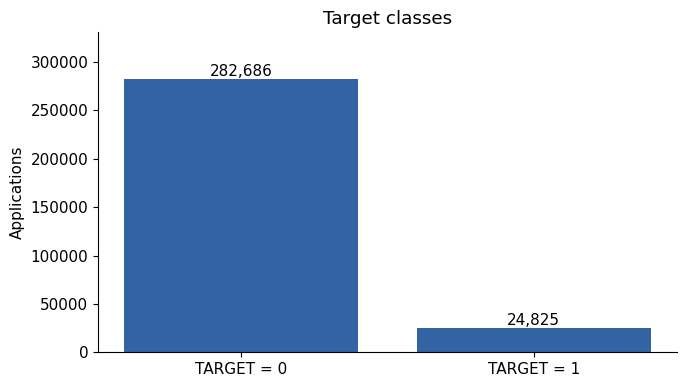

Positive rate:8.0729%


In [3]:
counts = pd.Series(quality["label_counts"]).rename(index={"0": "TARGET = 0", "1": "TARGET = 1"})
fig, ax = plt.subplots(figsize=(7, 4))
ax.bar(counts.index, counts.values, color="#3264A3")
ax.set(ylabel="Applications", title="Target classes", ylim=(0, counts.max()*1.17))
for i, value in enumerate(counts):
    ax.text(i, value, f"{value:,}", ha="center", va="bottom")
fig.tight_layout()
fig.savefig(RUN / "label_distribution.png", dpi=160)
plt.show()
print(f"Positive rate:{quality['payment_difficulty_fraction']:.4%}")


## 4. Check missing values

Read the saved missing rates and show the 12 columns with the most missing values in the training data.

During training, numeric gaps were filled with training-fold medians. Extra columns marked where values were missing. Missing text values formed their own category. The special employment value `365243` was also treated as missing and marked. This cell only shows the rates.


,train_missing_fraction,test_missing_fraction
COMMONAREA_AVG,0.6987,0.6872
COMMONAREA_MEDI,0.6987,0.6872
COMMONAREA_MODE,0.6987,0.6872
NONLIVINGAPARTMENTS_AVG,0.6943,0.6841
NONLIVINGAPARTMENTS_MEDI,0.6943,0.6841
NONLIVINGAPARTMENTS_MODE,0.6943,0.6841
FONDKAPREMONT_MODE,0.6839,0.6728
LIVINGAPARTMENTS_MEDI,0.6835,0.6725
LIVINGAPARTMENTS_AVG,0.6835,0.6725
LIVINGAPARTMENTS_MODE,0.6835,0.6725


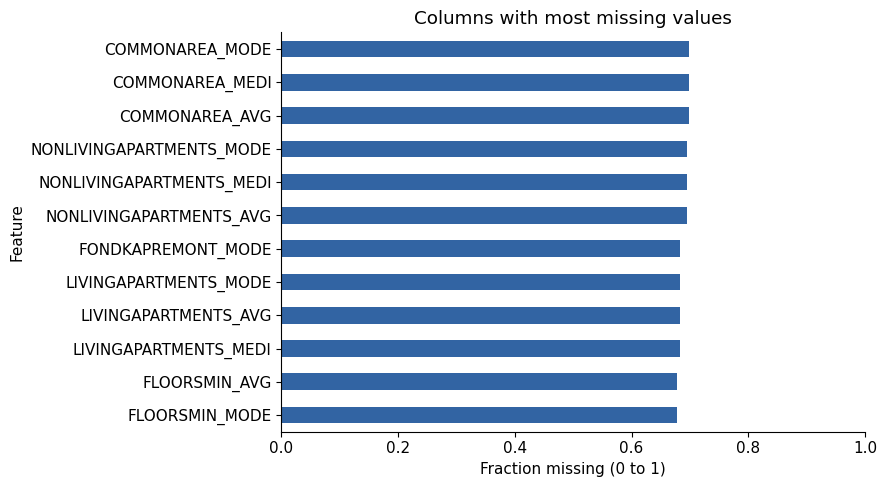

In [4]:
missing = pd.read_csv(ROOT / "outputs/data_quality/missingness_train_test.csv", index_col=0)
display(missing.head(12).round(4))
fig, ax = plt.subplots(figsize=(9, 5))
missing.head(12).sort_values("train_missing_fraction")["train_missing_fraction"].plot.barh(ax=ax, color="#3264A3")
ax.set(xlim=(0, 1), xlabel="Fraction missing (0 to 1)", ylabel="Feature", title="Columns with most missing values")
fig.tight_layout()
fig.savefig(RUN / "missingness.png", dpi=160)
plt.show()


## 5. Compare model scores

The table shows mean AUC and standard deviation across five folds. AP and Brier use all OOF predictions together. `seconds` is the recorded time for fitting and prediction.

Each dot in the plot is a mean AUC, with a bar for fold standard deviation. AUC and AP are better when higher; Brier is better when lower. These development scores were used to choose a model. The holdout is scored separately.


,experiment,cv_auc_mean,cv_auc_std,oof_average_precision,oof_brier_score,seconds
0,lightgbm_with_bureau,0.769274,0.002046,0.255307,0.067201,47.941668
1,lightgbm_engineered,0.764735,0.001558,0.248028,0.067542,43.899618
2,lightgbm_raw,0.756951,0.001472,0.239710,0.067972,41.145048
3,logistic_engineered,0.749725,0.003211,0.228700,0.068436,34.219740
4,logistic_raw,0.747588,0.003281,0.224764,0.068607,34.422309
5,lightgbm_no_external,0.714694,0.001003,0.190522,0.070279,41.737795
6,dummy_prior,0.500000,0.000000,0.080729,0.074212,10.452667


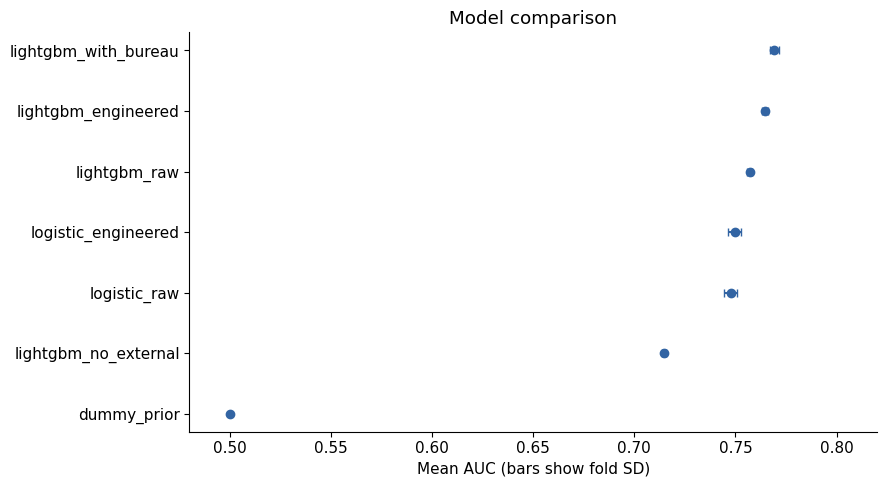

In [5]:
summary = pd.read_csv(RUN / "cv_summary.csv")
columns_to_show = [
    "experiment", "cv_auc_mean", "cv_auc_std",
    "oof_average_precision", "oof_brier_score", "seconds",
]
display(summary[columns_to_show].round(6))
ordered = summary.sort_values("cv_auc_mean")
positions = range(len(ordered))
fig, ax = plt.subplots(figsize=(9, 5))
ax.errorbar(ordered["cv_auc_mean"], positions,
            xerr=ordered["cv_auc_std"], fmt="o", color="#3264A3", capsize=3)
ax.set_yticks(positions, ordered["experiment"])
ax.set_xlim(0.48, 0.82)
ax.set_xlabel("Mean AUC (bars show fold SD)")
ax.set_title("Model comparison")
fig.tight_layout()
fig.savefig(RUN / "cv_comparison.png", dpi=160)
plt.show()


## 6. Compare the changes

For each change, subtract the two AUC scores within the same fold. The dot is the mean difference. The bar shows the smallest and largest fold differences, not a confidence interval.

A point to the right of zero means an improvement. The added feature set contains ratios, age and score summaries, so the result does not show the effect of ratios alone. Removing external scores also removes their summaries.


,comparison,mean_auc_delta,min_auc_delta,max_auc_delta,positive_folds,folds
0,raw_tree_vs_logistic,0.009363,0.004605,0.012094,5,5
1,logistic_engineering,0.002137,0.002007,0.002251,5,5
2,tree_engineering,0.007784,0.005049,0.009888,5,5
3,external_scores,0.050041,0.047495,0.052640,5,5
4,bureau_history,0.004539,0.003397,0.005510,5,5


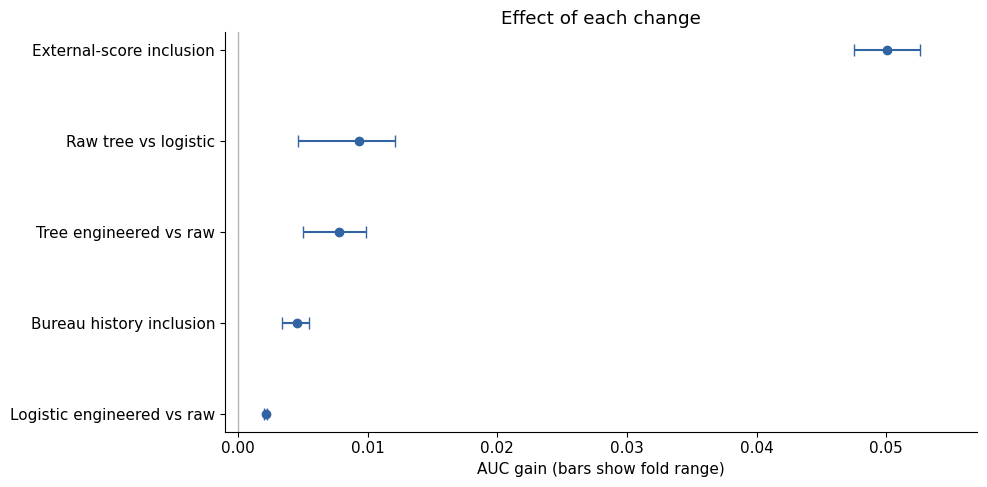

In [6]:
deltas = pd.read_csv(RUN / "paired_cv_deltas.csv")
display(deltas.round(6))
labels = {
    "raw_tree_vs_logistic": "Raw tree vs logistic",
    "logistic_engineering": "Logistic engineered vs raw",
    "tree_engineering": "Tree engineered vs raw",
    "external_scores": "External-score inclusion",
    "bureau_history": "Bureau history inclusion",
}
ordered = deltas.sort_values("mean_auc_delta")
# Matplotlib expects distances from the mean, not interval endpoints.
left_error = ordered["mean_auc_delta"] - ordered["min_auc_delta"]
right_error = ordered["max_auc_delta"] - ordered["mean_auc_delta"]
errors = [left_error, right_error]
fig, ax = plt.subplots(figsize=(10, 5))
ax.errorbar(ordered.mean_auc_delta, range(len(ordered)), xerr=errors, fmt="o", capsize=4, color="#3264A3")
ax.set_yticks(range(len(ordered)), [labels[value] for value in ordered.comparison])
ax.axvline(0, color="0.7", linewidth=1)
ax.set(xlim=(-0.001, 0.057), xlabel="AUC gain (bars show fold range)", title="Effect of each change")
fig.tight_layout()
fig.savefig(RUN / "paired_feature_gains.png", dpi=160)
plt.show()


## 7. Check the final model

The chosen setup is `lightgbm_with_bureau`. It was fitted on the whole development set, then tested on the 61,503 holdout rows. We read its saved predictions and calculate AUC, AP and Brier again. Each score must match the saved value.

ROC shows how well the model ranks the two classes. The PR curve shows precision and recall for class 1. The calibration plot compares mean predicted risk with the actual positive rate in ten groups. The grey line means perfect agreement. Group averages do not tell us whether every small subgroup is well calibrated.


selected_experiment                                               lightgbm_with_bureau
n                                                                                61503
default_fraction                                                              0.080728
roc_auc                                                                       0.772647
average_precision                                                             0.268479
brier_score                                                                   0.066672
auc_fixed_prediction_bootstrap_95_interval    [0.7661504735454596, 0.7795674740160856]
Name: final_holdout, dtype: object

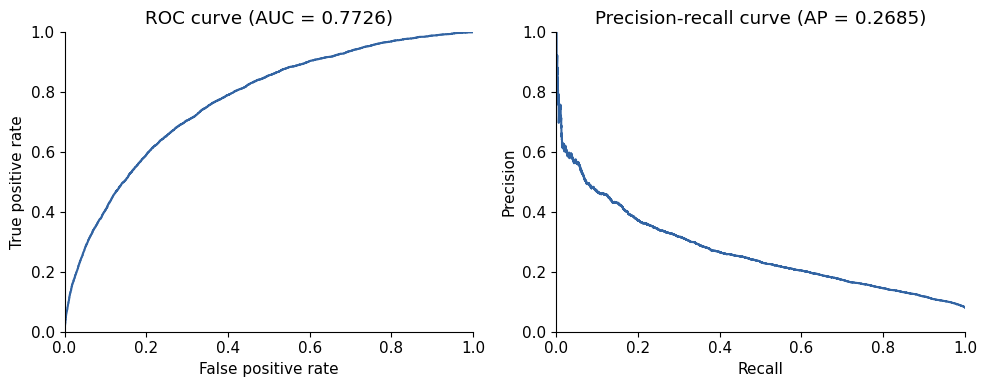

In [7]:
# Keep the metrics together and print the longer interval note in the next cell.
metric_values = {}
for key, value in metrics.items():
    if key != "interval_note":
        metric_values[key] = value

display(pd.Series(metric_values, name="final_holdout"))
predictions = pd.read_csv(RUN / "holdout_predictions.csv")
y_true = predictions["TARGET"]
y_prob = predictions["probability"]
fpr, tpr, thresholds = roc_curve(y_true, y_prob)
precision, recall, thresholds = precision_recall_curve(y_true, y_prob)

# Calculate the scores from the saved predictions, then check the saved metrics.
auc = roc_auc_score(y_true, y_prob)
ap = average_precision_score(y_true, y_prob)
brier = brier_score_loss(y_true, y_prob)
assert abs(auc - metrics["roc_auc"]) < 1e-10
assert abs(ap - metrics["average_precision"]) < 1e-10
assert abs(brier - metrics["brier_score"]) < 1e-10

fig, axes = plt.subplots(1, 2, figsize=(10, 4))
axes[0].plot(fpr, tpr, color="#3264A3")
axes[0].set_xlabel("False positive rate")
axes[0].set_ylabel("True positive rate")
axes[0].set_title(f"ROC curve (AUC = {auc:.4f})")
axes[1].plot(recall, precision, color="#3264A3")
axes[1].set_xlabel("Recall")
axes[1].set_ylabel("Precision")
axes[1].set_title(f"Precision-recall curve (AP = {ap:.4f})")
for ax in axes:
    ax.set_xlim(0, 1)
    ax.set_ylim(0, 1)
fig.tight_layout()
fig.savefig(RUN / "holdout_curves.png", dpi=160)
plt.show()


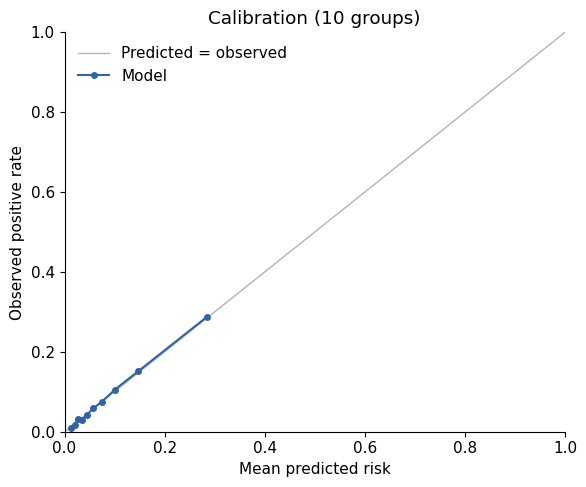

Stratified application bootstrap, 1000 draws; conditional on this fitted model. Does not include training/model-selection uncertainty.


In [8]:
# Use the same ten equal-size groups as the original plot.
observed, predicted = calibration_curve(y_true, y_prob, n_bins=10, strategy="quantile")
fig, ax = plt.subplots(figsize=(6, 5))
ax.plot([0, 1], [0, 1], color="0.7", linewidth=1, label="Predicted = observed")
ax.plot(predicted, observed, "o-", color="#3264A3", markersize=4, label="Model")
ax.set_xlim(0, 1)
ax.set_ylim(0, 1)
ax.set_xlabel("Mean predicted risk")
ax.set_ylabel("Observed positive rate")
ax.set_title("Calibration (10 groups)")
ax.legend(frameon=False)
fig.tight_layout()
fig.savefig(RUN / "holdout_calibration.png", dpi=160)
plt.show()
print(metrics["interval_note"])


## 8. Look at the main features

Gain measures how much tree splits using a feature improved the training objective. Show the 15 features with the highest gain. Remove `numeric__` from the labels to make them shorter.

High gain means the model used a feature strongly. It does not show whether the feature raises or lowers risk, or whether it causes payment difficulties. Related features may share their importance.


,encoded_feature,training_gain
0,numeric__EXT_SOURCE_MEAN,92966.664899
1,numeric__EXT_SOURCE_3,21262.710167
2,numeric__ANNUITY_CREDIT_RATIO,20008.505002
3,numeric__EXT_SOURCE_2,13618.210164
4,numeric__CREDIT_GOODS_RATIO,9465.006303
5,numeric__DAYS_BIRTH,6196.801056
6,numeric__BUREAU_DAYS_CREDIT_MAX,5145.399801
7,numeric__AMT_ANNUITY,5092.960624
8,numeric__EXT_SOURCE_1,4908.749741
9,numeric__DAYS_EMPLOYED,4885.931676


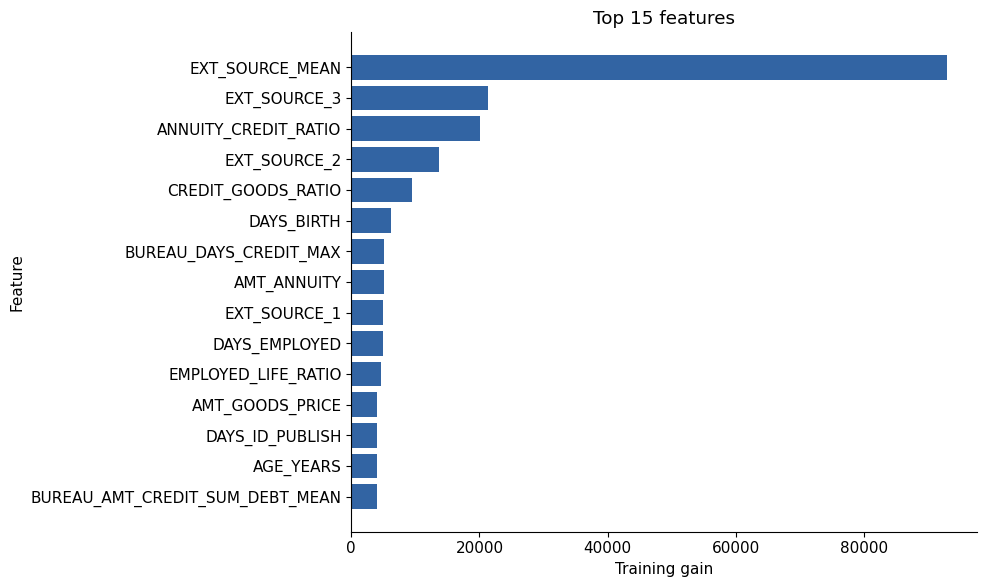

In [9]:
importance = pd.read_csv(RUN / "training_gain_importance.csv")
display(importance.head(15))
fig, ax = plt.subplots(figsize=(10, 6))
top = importance.head(15).sort_values("training_gain")
feature_names = top["encoded_feature"].str.replace("numeric__", "", regex=False)
ax.barh(feature_names, top["training_gain"], color="#3264A3")
ax.set(xlim=(0, top.training_gain.max()*1.05), xlabel="Training gain", ylabel="Feature", title="Top 15 features")
fig.tight_layout()
fig.savefig(RUN / "training_gain_top15.png", dpi=160)
plt.show()


## 9. Read the result checks

`src/check_results.py` checked the saved scores, labels, splits and models. Display its record below, then count the submission rows.

This cell does not rerun that whole script. Having a submission file does not mean it was sent to Kaggle.


In [10]:
check_names = [
    "status", "folds_checked", "development_rows", "holdout_rows",
    "fixed_seed_splits_verified", "oof_labels_and_fold_membership_verified",
    "model_reload_predictions_verified", "development_only_imputation_verified",
    "submission_ids_probabilities_and_model_verified", "frozen_plan_input_and_code_hashes_verified",
    "logistic_convergence_verified",
]
checks = {}
for name in check_names:
    checks[name] = validation[name]

display(pd.Series(checks, name="independent_checks"))
print("Submission rows:", len(pd.read_csv(RUN / "submission.csv")))


status                                             passed
folds_checked                                          35
development_rows                                   246008
holdout_rows                                        61503
fixed_seed_splits_verified                           True
oof_labels_and_fold_membership_verified              True
model_reload_predictions_verified                    True
development_only_imputation_verified                 True
submission_ids_probabilities_and_model_verified      True
frozen_plan_input_and_code_hashes_verified           True
logistic_convergence_verified                        True
Name: independent_checks, dtype: object

Submission rows: 48744


## What we found

With the original features, LightGBM has about 0.00936 higher mean AUC than logistic regression. Adding the new feature set raises AUC by about 0.00214 for logistic regression and 0.00778 for LightGBM.

Removing external scores and their summaries lowers AUC by about 0.05004. This is the largest change tested here. It shows how much the models use these scores across the full sample, not their performance only on people with missing scores. Adding bureau features gives a further gain of about 0.00454.

All five comparisons have positive differences in all five folds. The folds share training rows, so they are not five independent tests. The final holdout AUC is about 0.77265, with a bootstrap interval of [0.766150, 0.779567]. This interval holds the fitted model fixed.

The results apply to this data and random split. They do not test future loans. The report should state each member's work and the use of AI tools.

For a new training run, use the full-data command with `--with-bureau` in the README and a new output folder. Change `RUN` here to read that folder. Keep the old files for comparison.
